In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import os


In [8]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/feature_engineering/espectros_estatisticas_Descritivas.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/feature_engineering"
output_path = os.path.join(output_dir, 'espectros_derivadasLocais_bandasSelecionadas.csv')

In [9]:
df = pd.read_csv(input_path)

In [10]:
derivadas = df.diff(axis=1).iloc[:, 1:]  # remove primeira coluna NaN
derivadas.columns = [f"deriv_{col}" for col in derivadas.columns]

In [11]:
indices_para_razao = [(0, 1), (1, 2)]
razoes = pd.DataFrame(index=df.index)

for i, j in indices_para_razao:
    razoes[f"razao_col{i}_col{j}"] = df.iloc[:, i] / df.iloc[:, j]

In [12]:
data_features = pd.concat([derivadas, razoes], axis=1)

# Exibe primeiras linhas
print(data_features.head())

   deriv_desvio_padrao  deriv_curtose  deriv_skewness  razao_col0_col1  \
0             1.435968       7.247350      -11.473377        -0.306472   
1             1.438195       7.245376      -11.475780        -0.303946   
2             0.026035       2.632927       -4.461090        -0.038664   
3             0.025006       3.571883       -5.480607        -0.202468   
4             0.033897       5.314908       -7.835862        -0.072247   

   razao_col1_col2  
0         0.131687  
1         0.132117  
2         0.009430  
3         0.005788  
4         0.005913  


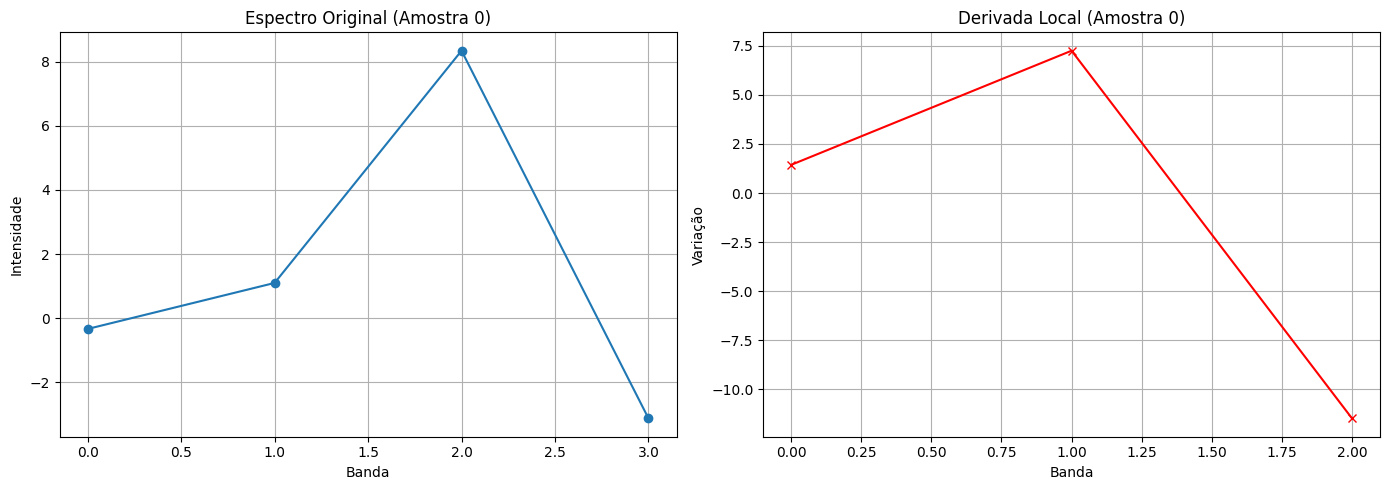

In [13]:
sample_idx = 0
original = df.iloc[sample_idx].values
derivada = derivadas.iloc[sample_idx].values

plt.figure(figsize=(14,5))

# Plot espectro original
plt.subplot(1,2,1)
plt.plot(original, marker='o')
plt.title(f"Espectro Original (Amostra {sample_idx})")
plt.xlabel("Banda")
plt.ylabel("Intensidade")
plt.grid(True)

# Plot derivada
plt.subplot(1,2,2)
plt.plot(derivada, marker='x', color="red")
plt.title(f"Derivada Local (Amostra {sample_idx})")
plt.xlabel("Banda")
plt.ylabel("Variação")
plt.grid(True)

plt.tight_layout()
plt.show()